In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\Adnan Baismail\Downloads\archive (6)\weather_classification_data.csv")
df

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy
1,39.0,96,8.5,71.0,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy
2,30.0,64,7.0,16.0,clear,1018.72,5,Spring,5.5,mountain,Sunny
3,38.0,83,1.5,82.0,clear,1026.25,7,Spring,1.0,coastal,Sunny
4,27.0,74,17.0,66.0,overcast,990.67,1,Winter,2.5,mountain,Rainy
...,...,...,...,...,...,...,...,...,...,...,...
13195,10.0,74,14.5,71.0,overcast,1003.15,1,Summer,1.0,mountain,Rainy
13196,-1.0,76,3.5,23.0,cloudy,1067.23,1,Winter,6.0,coastal,Snowy
13197,30.0,77,5.5,28.0,overcast,1012.69,3,Autumn,9.0,coastal,Cloudy
13198,3.0,76,10.0,94.0,overcast,984.27,0,Winter,2.0,inland,Snowy


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           13200 non-null  float64
 1   Humidity              13200 non-null  int64  
 2   Wind Speed            13200 non-null  float64
 3   Precipitation (%)     13200 non-null  float64
 4   Cloud Cover           13200 non-null  object 
 5   Atmospheric Pressure  13200 non-null  float64
 6   UV Index              13200 non-null  int64  
 7   Season                13200 non-null  object 
 8   Visibility (km)       13200 non-null  float64
 9   Location              13200 non-null  object 
 10  Weather Type          13200 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 1.1+ MB


In [4]:
df['Weather Type'].unique()

array(['Rainy', 'Cloudy', 'Sunny', 'Snowy'], dtype=object)

In [5]:
df['Season'].unique()

array(['Winter', 'Spring', 'Summer', 'Autumn'], dtype=object)

In [6]:
cat=[]
for i in df.columns:
    if df[i].dtype=='O':
        print(i,df[i].unique())
        cat.append(i)

Cloud Cover ['partly cloudy' 'clear' 'overcast' 'cloudy']
Season ['Winter' 'Spring' 'Summer' 'Autumn']
Location ['inland' 'mountain' 'coastal']
Weather Type ['Rainy' 'Cloudy' 'Sunny' 'Snowy']


In [7]:
num=df.drop(df[cat],axis=1)
num

,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km)
0,14.0,73,9.5,82.0,1010.82,2,3.5
1,39.0,96,8.5,71.0,1011.43,7,10.0
2,30.0,64,7.0,16.0,1018.72,5,5.5
3,38.0,83,1.5,82.0,1026.25,7,1.0
4,27.0,74,17.0,66.0,990.67,1,2.5
...,...,...,...,...,...,...,...
13195,10.0,74,14.5,71.0,1003.15,1,1.0
13196,-1.0,76,3.5,23.0,1067.23,1,6.0
13197,30.0,77,5.5,28.0,1012.69,3,9.0
13198,3.0,76,10.0,94.0,984.27,0,2.0


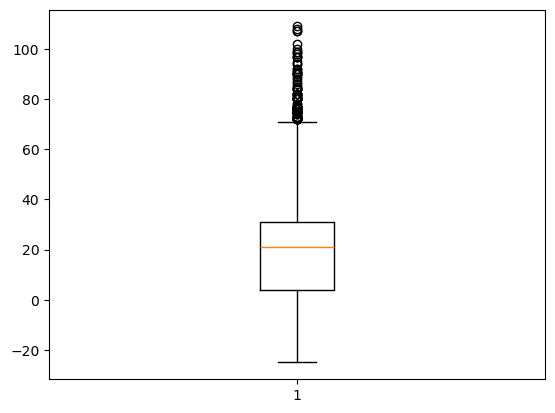

In [8]:
plt.boxplot(df['Temperature'])
plt.show()

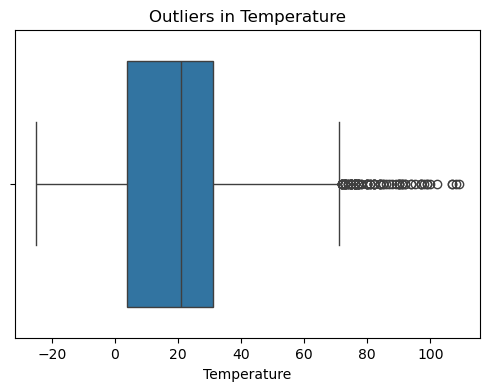

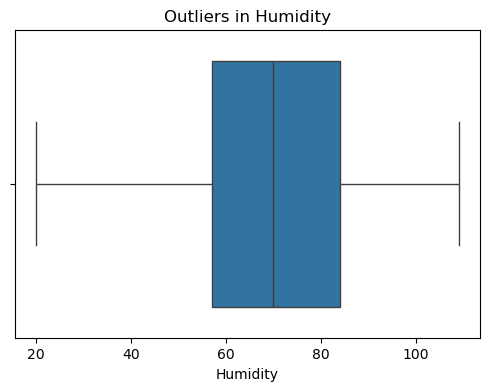

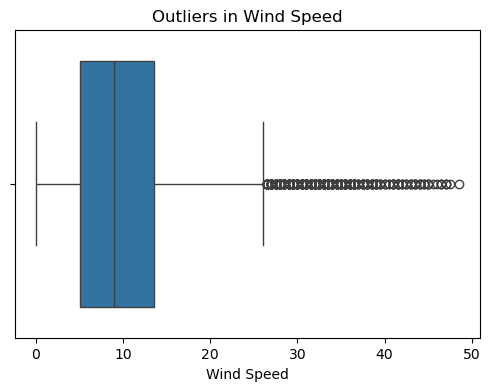

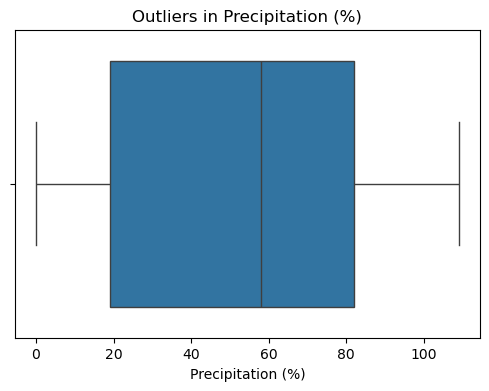

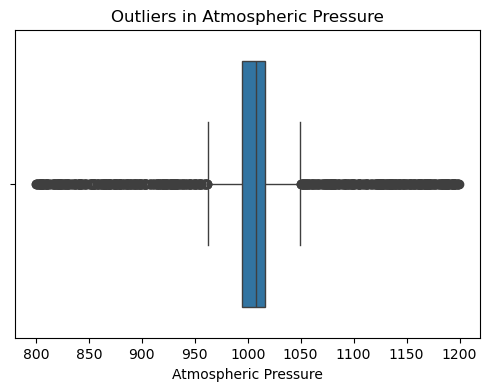

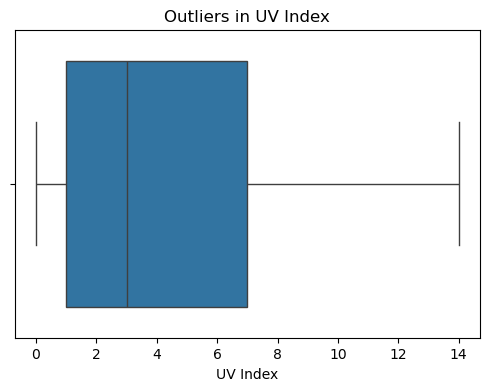

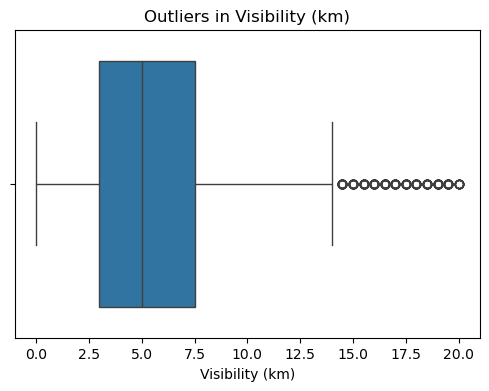

In [9]:

import seaborn as sns
import matplotlib.pyplot as plt

for i in num:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[i])
    plt.title(f'Outliers in {i}')
    plt.show()


In [10]:
cat

['Cloud Cover', 'Season', 'Location', 'Weather Type']

In [11]:
from sklearn.preprocessing import OrdinalEncoder
O = OrdinalEncoder(categories=[
    ['partly cloudy','clear', 'overcast', 'cloudy'],
    ['Winter', 'Spring' ,'Summer' ,'Autumn'],
    ['inland', 'mountain' ,'coastal'],
    ['Rainy', 'Cloudy' ,'Sunny' ,'Snowy']
])
df[cat]=O.fit_transform(df[cat])

In [12]:
df

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,0.0,1010.82,2,0.0,3.5,0.0,0.0
1,39.0,96,8.5,71.0,0.0,1011.43,7,1.0,10.0,0.0,1.0
2,30.0,64,7.0,16.0,1.0,1018.72,5,1.0,5.5,1.0,2.0
3,38.0,83,1.5,82.0,1.0,1026.25,7,1.0,1.0,2.0,2.0
4,27.0,74,17.0,66.0,2.0,990.67,1,0.0,2.5,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
13195,10.0,74,14.5,71.0,2.0,1003.15,1,2.0,1.0,1.0,0.0
13196,-1.0,76,3.5,23.0,3.0,1067.23,1,0.0,6.0,2.0,3.0
13197,30.0,77,5.5,28.0,2.0,1012.69,3,3.0,9.0,2.0,1.0
13198,3.0,76,10.0,94.0,2.0,984.27,0,0.0,2.0,0.0,3.0


In [13]:
T=df['Weather Type']

In [14]:
F=df.drop('Weather Type',axis=1)

In [15]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(F,T,test_size=0.2,random_state=42)

In [16]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [17]:
print(X_train)

[[ 0.72798445 -0.129706   -0.5536792  ... -0.12699076 -1.17954402
  -1.14914191]
 [-0.2483393   1.35248791  0.17067625 ...  1.59006745 -0.4360718
   0.11110719]
 [ 0.49826122 -0.52495771 -0.48124366 ...  0.73153834  1.05087263
  -1.14914191]
 ...
 [ 0.84284607 -0.82139649 -0.40880811 ...  0.73153834  0.75348375
   1.37135628]
 [-0.59292416  0.21613924  0.02580516 ... -0.12699076  0.75348375
   0.11110719]
 [-0.47806254  1.30308144 -0.62611475 ...  1.59006745 -0.4360718
   1.37135628]]


# LogisticRegression

In [18]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()
lr.fit(X_train,Y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [19]:
from sklearn.metrics import accuracy_score,classification_report
y_pred=lr.predict(X_test)
print(classification_report(Y_test,y_pred))
print(accuracy_score(Y_test, y_pred))

LR=accuracy_score(Y_test, y_pred)

              precision    recall  f1-score   support

         0.0       0.84      0.82      0.83       647
         1.0       0.83      0.82      0.82       651
         2.0       0.86      0.84      0.85       641
         3.0       0.88      0.94      0.91       701

    accuracy                           0.85      2640
   macro avg       0.85      0.85      0.85      2640
weighted avg       0.85      0.85      0.85      2640

0.8545454545454545


# Naive Bayes

In [20]:
from sklearn.naive_bayes import GaussianNB
nb=GaussianNB()
nb.fit(X_train,Y_train)

,priors,None
,var_smoothing,1e-09


In [21]:
from sklearn.metrics import accuracy_score, classification_report
nb_y_pred=nb.predict(X_test)
print(classification_report(Y_test,nb_y_pred))
print(accuracy_score(Y_test, nb_y_pred))
NV=accuracy_score(Y_test, nb_y_pred)

              precision    recall  f1-score   support

         0.0       0.80      0.84      0.82       647
         1.0       0.89      0.80      0.84       651
         2.0       0.84      0.87      0.85       641
         3.0       0.91      0.94      0.92       701

    accuracy                           0.86      2640
   macro avg       0.86      0.86      0.86      2640
weighted avg       0.86      0.86      0.86      2640

0.8613636363636363


# Decision Tree

In [22]:
from sklearn.tree import DecisionTreeClassifier
DT=DecisionTreeClassifier()
DT.fit(X_train,Y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [23]:
from sklearn.metrics import classification_report
DT_y_pred=DT.predict(X_test)
print(classification_report(Y_test,DT_y_pred))
print(accuracy_score(Y_test, DT_y_pred))
DT=accuracy_score(Y_test, DT_y_pred)

              precision    recall  f1-score   support

         0.0       0.90      0.89      0.90       647
         1.0       0.88      0.89      0.88       651
         2.0       0.92      0.90      0.91       641
         3.0       0.93      0.95      0.94       701

    accuracy                           0.91      2640
   macro avg       0.91      0.91      0.91      2640
weighted avg       0.91      0.91      0.91      2640

0.9102272727272728


# k-Nearest-Neighbors(KNN)

In [24]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train,Y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [25]:
from sklearn.metrics import accuracy_score, classification_report
knn_y_pred=knn.predict(X_test)

In [26]:
print(classification_report(Y_test,knn_y_pred))
print(accuracy_score(Y_test, knn_y_pred))
knn=accuracy_score(Y_test, knn_y_pred)

              precision    recall  f1-score   support

         0.0       0.84      0.90      0.87       647
         1.0       0.87      0.86      0.87       651
         2.0       0.91      0.87      0.89       641
         3.0       0.94      0.93      0.94       701

    accuracy                           0.89      2640
   macro avg       0.89      0.89      0.89      2640
weighted avg       0.89      0.89      0.89      2640

0.8916666666666667


# ENSEMBLE LEARNING

# BAGGING

In [27]:
from sklearn.ensemble import BaggingClassifier
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=60,
    random_state=42
)
bagging.fit(X_train, Y_train)


,estimator,DecisionTreeClassifier()
,n_estimators,60
,max_samples,1.0
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,False
,warm_start,False
,n_jobs,None
,random_state,42
,verbose,0


In [28]:
from sklearn.metrics import classification_report
bag_y_pred=bagging.predict(X_test)
print(classification_report(Y_test,bag_y_pred))


              precision    recall  f1-score   support

         0.0       0.90      0.90      0.90       647
         1.0       0.89      0.90      0.89       651
         2.0       0.93      0.90      0.91       641
         3.0       0.93      0.95      0.94       701

    accuracy                           0.91      2640
   macro avg       0.91      0.91      0.91      2640
weighted avg       0.91      0.91      0.91      2640



In [29]:
from sklearn.metrics import accuracy_score
print("Bagging Accuracy:", accuracy_score(Y_test, bag_y_pred))
bag=accuracy_score(Y_test, bag_y_pred)


Bagging Accuracy: 0.9125


In [30]:
bag

0.9125

# BOOSTING

In [31]:
from sklearn.ensemble import GradientBoostingClassifier

boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)
boosting.fit(X_train, Y_train)


,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [32]:
from sklearn.metrics import classification_report
bst_y_pred=boosting.predict(X_test)
print(classification_report(Y_test,bst_y_pred))

              precision    recall  f1-score   support

         0.0       0.90      0.91      0.90       647
         1.0       0.88      0.88      0.88       651
         2.0       0.93      0.90      0.92       641
         3.0       0.92      0.95      0.94       701

    accuracy                           0.91      2640
   macro avg       0.91      0.91      0.91      2640
weighted avg       0.91      0.91      0.91      2640



In [33]:
print(accuracy_score(Y_test, bst_y_pred))
boost=accuracy_score(Y_test, bst_y_pred)

0.9109848484848485


# VOTING

In [34]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB


In [35]:
model1 = LogisticRegression(max_iter=1000)
model2 = DecisionTreeClassifier()
model3 = GaussianNB()

In [36]:
voting_hard = VotingClassifier(
    estimators=[
        ('lr', model1),
        ('dt', model2),
        ('nb', model3)
    ],
    voting='hard'
)
voting_hard.fit(X_train, Y_train)


,estimators,"[('lr', ...), ('dt', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True


#   Hard voting

In [37]:
Voting_Hard=voting_hard.predict(X_test)
print(classification_report(Y_test,Voting_Hard))


              precision    recall  f1-score   support

         0.0       0.82      0.87      0.84       647
         1.0       0.89      0.83      0.86       651
         2.0       0.89      0.85      0.87       641
         3.0       0.91      0.94      0.92       701

    accuracy                           0.87      2640
   macro avg       0.87      0.87      0.87      2640
weighted avg       0.88      0.87      0.87      2640



In [38]:
print("Hard Voting Accuracy:", accuracy_score(Y_test, voting_hard.predict(X_test)))
hard_voting=accuracy_score(Y_test, voting_hard.predict(X_test))

Hard Voting Accuracy: 0.8742424242424243


#  soft voting

In [39]:
voting_soft = VotingClassifier(
    estimators=[
        ('lr', model1),
        ('dt', model2),
        ('nb', model3)
    ],
    voting='soft'
)
voting_soft.fit(X_train, Y_train)

,estimators,"[('lr', ...), ('dt', ...), ...]"
,voting,'soft'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True


In [40]:
Voting_soft=voting_soft.predict(X_test)
print(classification_report(Y_test,Voting_soft))



              precision    recall  f1-score   support

         0.0       0.85      0.90      0.87       647
         1.0       0.90      0.84      0.87       651
         2.0       0.88      0.89      0.88       641
         3.0       0.94      0.94      0.94       701

    accuracy                           0.89      2640
   macro avg       0.89      0.89      0.89      2640
weighted avg       0.89      0.89      0.89      2640



In [41]:
print("soft Voting Accuracy:", accuracy_score(Y_test, voting_soft.predict(X_test)))
soft_voting=accuracy_score(Y_test, voting_soft.predict(X_test))

soft Voting Accuracy: 0.8920454545454546


# STACKING

In [42]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

estimators = [
    ('DT', DecisionTreeClassifier()),
    ('svc', SVC(probability=True)),
    ('NB',GaussianNB())
]
stack = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression()
)
stack.fit(X_train, Y_train)
Stk_y_pred = stack.predict(X_test)
print("Stacking Accuracy:", accuracy_score(Y_test, Stk_y_pred))


Stacking Accuracy: 0.9087121212121212


In [43]:
print(classification_report(Y_test,Stk_y_pred))


              precision    recall  f1-score   support

         0.0       0.90      0.90      0.90       647
         1.0       0.88      0.90      0.89       651
         2.0       0.91      0.89      0.90       641
         3.0       0.94      0.94      0.94       701

    accuracy                           0.91      2640
   macro avg       0.91      0.91      0.91      2640
weighted avg       0.91      0.91      0.91      2640



In [44]:
stacking=accuracy_score(Y_test, Stk_y_pred)

In [49]:

data = {
    'LR': LR,
    'NV': NV,
    'DT': DT,
    'KNN': knn,
    'Bagging': bag,
    'Boosting': boost,
    'Hard Voting': hard_voting,
    'Soft Voting': soft_voting,
    'Stacking': stacking
}

df2 = pd.DataFrame(list(data.items()), columns=['Model', 'Accuracy'])

print(df2)

         Model  Accuracy
0           LR  0.854545
1           NV  0.861364
2           DT  0.910227
3          KNN  0.891667
4      Bagging  0.912500
5     Boosting  0.910985
6  Hard Voting  0.874242
7  Soft Voting  0.892045
8     Stacking  0.908712


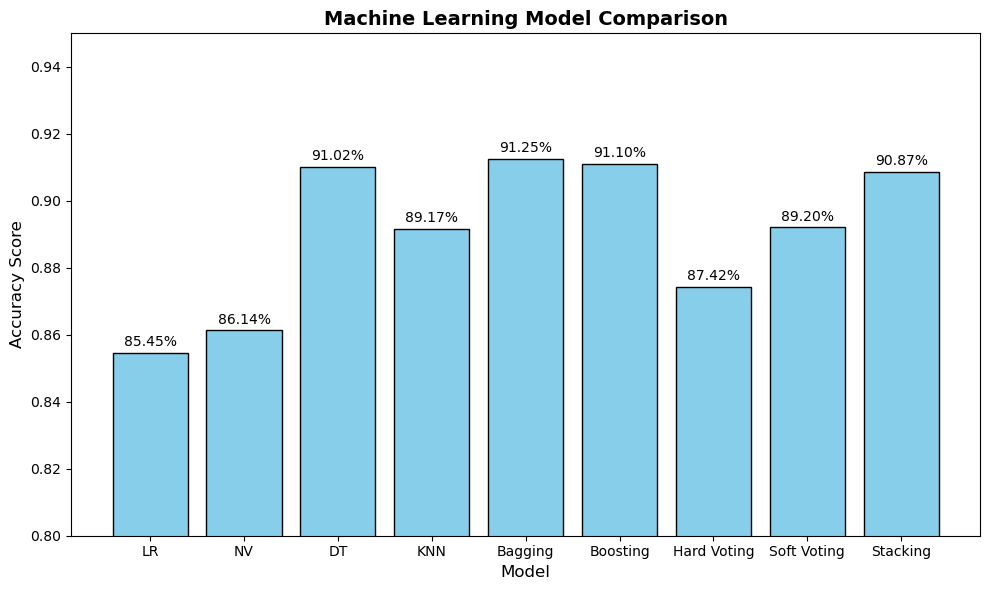

In [50]:
plt.figure(figsize=(10, 6)) 
bars = plt.bar(df2['Model'], df2['Accuracy'], color='skyblue', edgecolor='black')
plt.title('Machine Learning Model Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Model', fontsize=12)
plt.ylabel('Accuracy Score', fontsize=12)
plt.ylim(0.80, 0.95)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.002, f"{yval * 100:.2f}%", ha='center', fontsize=10)

plt.tight_layout()
plt.show()

In [51]:
df2 = df2.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)
df2['Accuracy (%)'] = (df2['Accuracy'] * 100).round(2)
print(df2[['Model', 'Accuracy (%)']])

         Model  Accuracy (%)
0      Bagging         91.25
1     Boosting         91.10
2           DT         91.02
3     Stacking         90.87
4  Soft Voting         89.20
5          KNN         89.17
6  Hard Voting         87.42
7           NV         86.14
8           LR         85.45


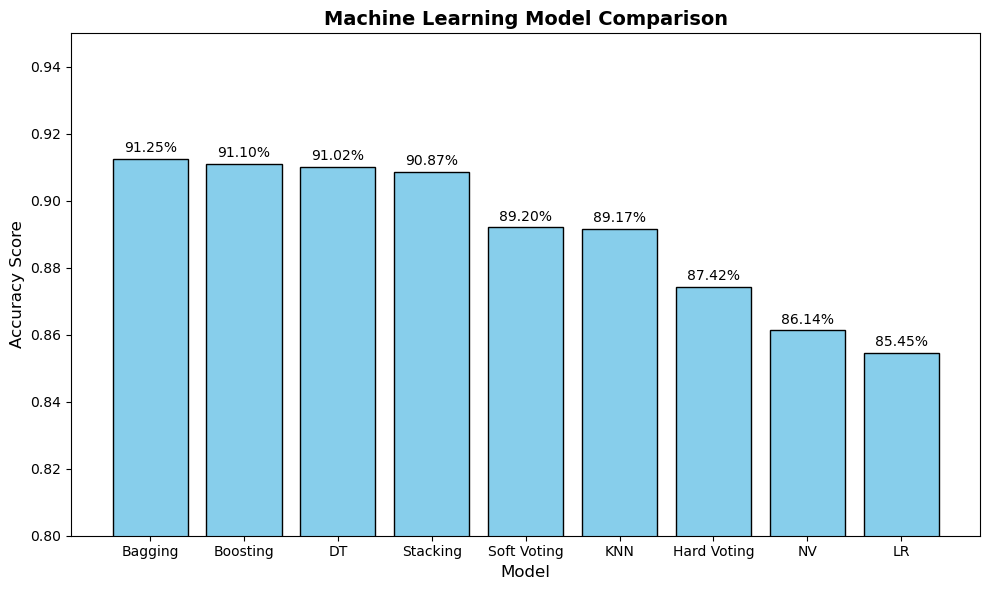

In [53]:
df2_sorted = df2.sort_values(by='Accuracy', ascending=False)

plt.figure(figsize=(10, 6))
bars = plt.bar(df2_sorted['Model'], df2_sorted['Accuracy'], color='skyblue', edgecolor='black')
plt.title('Machine Learning Model Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Model', fontsize=12)
plt.ylabel('Accuracy Score', fontsize=12)
plt.ylim(0.80, 0.95)
#plt.xticks(rotation=25)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.002, f"{yval * 100:.2f}%", ha='center', fontsize=10)

plt.tight_layout()
plt.show()